In [2]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("prasunroy/natural-images")
path=os.path.join(path,"data","natural_images")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'natural-images' dataset.
Path to dataset files: /kaggle/input/natural-images/data/natural_images


In [3]:
import torch
from torchvision import transforms
from torchvision import datasets
from torch.utils.data import ConcatDataset,DataLoader

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.RandomResizedCrop(
        224,
        scale=(0.8, 1.0)
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [5]:
from torch.utils.data import random_split, DataLoader

# Create dataset twice so train and validation can have different transforms
train_full = datasets.ImageFolder(path, transform=train_transform)
print(train_full.classes)
print(len(train_full))
val_full = datasets.ImageFolder(path, transform=val_transform)

# 80/20 split
train_size = int(0.8 * len(train_full))
val_size = len(train_full) - train_size

generator = torch.Generator().manual_seed(42)

train_data, _ = random_split(
    train_full,
    [train_size, val_size],
    generator=generator
)

_, test_data = random_split(
    val_full,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=32,
    shuffle=False,
    pin_memory=True
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))
print("Classes:", train_full.classes)

['airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike', 'person']
6899
Training images: 5519
Testing images: 1380
Classes: ['airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike', 'person']


In [6]:
import torch.nn as nn
import torch.optim as optim

train_loader = DataLoader(train_data, batch_size=32, shuffle=True,pin_memory=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

In [7]:
image, label = train_data[0]

print("Image shape:", image.shape)
print("Label:", label)

Image shape: torch.Size([3, 224, 224])
Label: 5


In [8]:
class MyNN(nn.Module):
    def __init__(self, input_features):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(input_features, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.3),
            nn.Conv2d(128, 256 , kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)

        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256*14*14, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 8)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)

        return x

In [9]:
model=MyNN(3)
print(model)

MyNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout(p=0.2, inplace=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU()
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Dropout(p=0.3, inplace=False)
    (11): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplac

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
model = model.to(device)

cuda


In [11]:
learning_rate = 0.001
epochs = 35

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)

In [12]:
for epoch in range(epochs):
    model.train()
    total_epoch_loss = 0

    correct=0
    total=0
    for image, label in train_loader:

        image = image.to(device)
        label = label.to(device)


        # forward pass
        outputs = model(image)

        # calculate loss
        loss = criterion(outputs, label)

        # back pass
        optimizer.zero_grad()
        loss.backward()

        # update grads
        optimizer.step()

        total_epoch_loss = total_epoch_loss + loss.item()

        _, predicted = torch.max(outputs, 1)

        total += label.size(0)

        correct += (predicted == label).sum().item()

    accuracy = 100 * correct / total

    avg_loss = total_epoch_loss/len(train_loader)
    print(f'Epoch: {epoch + 1} , Loss: {avg_loss}, Accuracy: {accuracy}')

Epoch: 1 , Loss: 1.3315719683046285, Accuracy: 53.016850878782385
Epoch: 2 , Loss: 0.6517125753998068, Accuracy: 76.9342272150752
Epoch: 3 , Loss: 0.4964382295319111, Accuracy: 81.64522558434498
Epoch: 4 , Loss: 0.4159236188138151, Accuracy: 83.63834027903606
Epoch: 5 , Loss: 0.3787656177502836, Accuracy: 86.1206740351513
Epoch: 6 , Loss: 0.34711049716768927, Accuracy: 86.91791991302772
Epoch: 7 , Loss: 0.3043945659102732, Accuracy: 89.12846530168508
Epoch: 8 , Loss: 0.28068317907910817, Accuracy: 89.1103460771879
Epoch: 9 , Loss: 0.2744174709898888, Accuracy: 89.9438304040587
Epoch: 10 , Loss: 0.2570410343048545, Accuracy: 90.3968110164885
Epoch: 11 , Loss: 0.24272682328272416, Accuracy: 91.32089146584526
Epoch: 12 , Loss: 0.2384964037751187, Accuracy: 91.12157999637616
Epoch: 13 , Loss: 0.22947819915336337, Accuracy: 91.26653379235368
Epoch: 14 , Loss: 0.20206352471874628, Accuracy: 92.42616416017394
Epoch: 15 , Loss: 0.2129349926583512, Accuracy: 92.33556803768799
Epoch: 16 , Loss: 

In [13]:
model.eval()

MyNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout(p=0.2, inplace=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU()
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Dropout(p=0.3, inplace=False)
    (11): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplac

In [14]:
correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Test Accuracy:", accuracy, "%")

Test Accuracy: 93.26086956521739 %


In [15]:
correct = 0
total = 0

with torch.no_grad():

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Train Accuracy:", accuracy, "%")

Train Accuracy: 97.0103279579634 %


In [16]:
all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predictions = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

In [17]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# all_labels and all_predictions should already contain
# the true labels and predicted labels from your test evaluation

precision = precision_score(
    all_labels,
    all_predictions,
    average='weighted'
)

recall = recall_score(
    all_labels,
    all_predictions,
    average='weighted'
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average='weighted'
)

print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=train_full.classes
))

Precision : 0.9366
Recall    : 0.9326
F1 Score  : 0.9319

Classification Report:
              precision    recall  f1-score   support

    airplane       0.94      0.96      0.95       139
         car       0.98      0.98      0.98       200
         cat       0.93      0.72      0.81       209
         dog       0.71      0.86      0.78       138
      flower       0.95      0.97      0.96       180
       fruit       1.00      1.00      1.00       172
   motorbike       0.96      1.00      0.98       170
      person       0.98      1.00      0.99       172

    accuracy                           0.93      1380
   macro avg       0.93      0.94      0.93      1380
weighted avg       0.94      0.93      0.93      1380



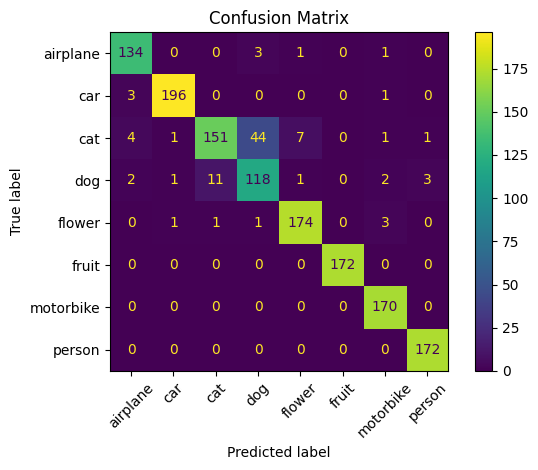

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_full.classes
)

disp.plot(xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()